# F1 Race Visualizations
**Notebook:** `notebooks/03_visualizations.ipynb`  
**Data:** `data/processed/cleaned_laps.csv` (5 races from the 2025 season, collected with [FastF1](https://github.com/theOehrly/Fast-F1))

This notebook produces three charts, saved to `reports/figures/`:
1. Speed trap comparison across teams
2. Lap time evolution in the Bahrain Grand Prix
3. Lap time vs tyre age for all races

**Filtering:** charts use laps where `IsAccurate == True`. This removes pit in/out laps, lap 1 and laps with unreliable timing. It does **not** remove safety car laps or laps deleted for track limits.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charts are saved to the reports/figures folder in the repo root
os.makedirs("../reports/figures", exist_ok=True)

# Load dataset
df = pd.read_csv("../data/processed/cleaned_laps.csv")
df_valid = df[df['IsAccurate'] == True].copy()

print("Shape:", df.shape)
print("Laps with IsAccurate == True:", len(df_valid))

Shape: (5305, 43)
Laps with IsAccurate == True: 4632


In [2]:
print("Races:", df['Race'].unique())
print("Drivers:", df['Driver'].unique())

Races: <StringArray>
['Bahrain', 'Monaco', 'Silverstone', 'Monza', 'Suzuka']
Length: 5, dtype: str
Drivers: <StringArray>
['PIA', 'RUS', 'NOR', 'LEC', 'GAS', 'SAI', 'ANT', 'VER', 'HAM', 'TSU', 'DOO',
 'ALO', 'OCO', 'ALB', 'BEA', 'HAD', 'LAW', 'STR', 'BOR', 'HUL', 'COL']
Length: 21, dtype: str


## 1. Speed trap comparison
Top speed at the speed trap (`SpeedST`) for the six teams with the most valid laps, across all five races.

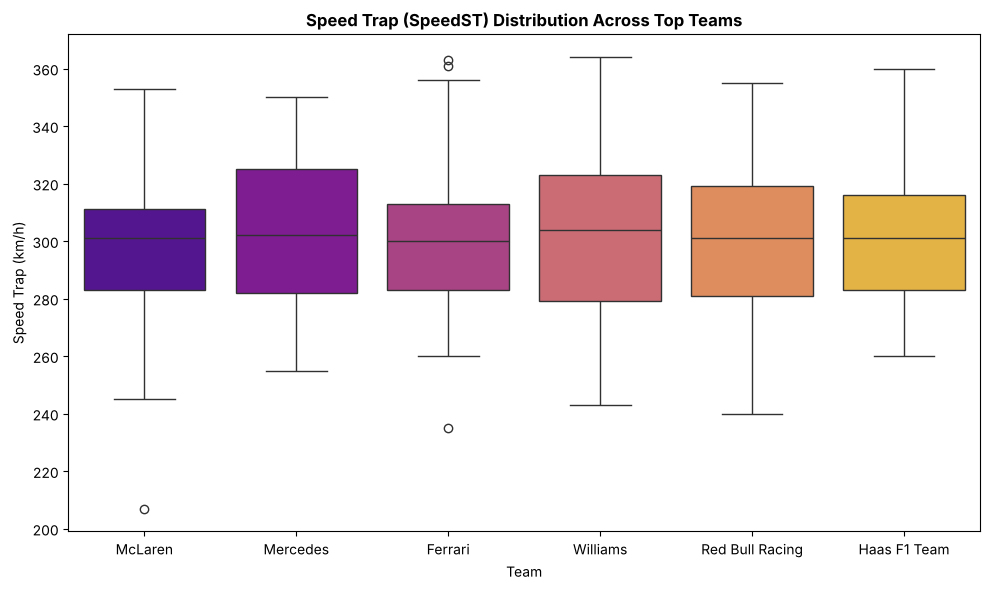

Team
Williams           304.0
Mercedes           302.0
McLaren            301.0
Haas F1 Team       301.0
Red Bull Racing    301.0
Ferrari            300.0
Name: SpeedST, dtype: float64

Race
Monaco         278.0
Suzuka         300.0
Bahrain        303.0
Silverstone    308.0
Monza          326.0
Name: SpeedST, dtype: float64


In [3]:
top_teams = df_valid['Team'].value_counts().head(6).index
df_teams = df_valid[df_valid['Team'].isin(top_teams)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_teams, x='Team', y='SpeedST', hue='Team', palette='plasma', legend=False)
plt.title("Speed Trap (SpeedST) Distribution Across Top Teams", fontweight='bold')
plt.xlabel("Team")
plt.ylabel("Speed Trap (km/h)")
plt.tight_layout()
plt.savefig("../reports/figures/top_speed_comparison.png", dpi=300)
plt.show()

# Median top speed per team, and per race
print(df_teams.groupby('Team')['SpeedST'].median().sort_values(ascending=False))
print()
print(df_valid.groupby('Race')['SpeedST'].median().sort_values())

### Findings
- The teams are very close: median speed trap values range from **300 km/h (Ferrari)** to **304 km/h (Williams)**.
- Most of the spread inside each box comes from the **track**, not the team. The median at Monaco is **278 km/h** compared with **326 km/h** at Monza.
- **Limitation:** because all five races are combined, this chart mixes very different circuits. Comparing teams within a single race would give a fairer picture.

## 2. Lap time evolution: Bahrain Grand Prix
Lap times for five front-running drivers across the race.

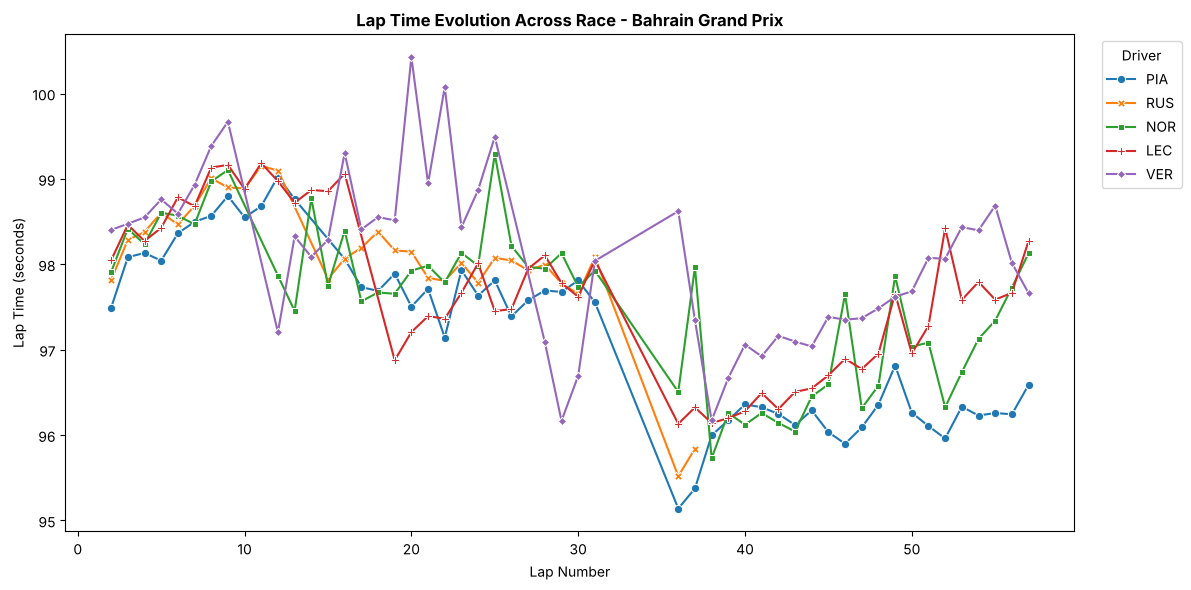

        Laps 2-10 (s)  Laps 48+ (s)
Driver                             
LEC             98.68         97.62
NOR             98.52         97.10
PIA             98.36         96.26
RUS             98.60           NaN
VER             98.68         98.04


In [4]:
df_bahrain = df_valid[(df_valid['Race'] == 'Bahrain') & (df_valid['LapTime_s'] < 115)]  # drop very slow outlier laps
top_drivers = ['VER', 'NOR', 'LEC', 'RUS', 'PIA']
df_bahrain_top = df_bahrain[df_bahrain['Driver'].isin(top_drivers)]

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_bahrain_top,
    x='LapNumber',
    y='LapTime_s',
    hue='Driver',
    style='Driver',
    markers=True,
    dashes=False
)
plt.title("Lap Time Evolution Across Race - Bahrain Grand Prix", fontweight='bold')
plt.xlabel("Lap Number")
plt.ylabel("Lap Time (seconds)")
plt.legend(title="Driver", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("../reports/figures/lap_time_evolution.png", dpi=300)
plt.show()

# Median lap time early vs late in the race
early = df_bahrain_top[df_bahrain_top['LapNumber'] <= 10].groupby('Driver')['LapTime_s'].median()
late = df_bahrain_top[df_bahrain_top['LapNumber'] >= 48].groupby('Driver')['LapTime_s'].median()
print(pd.DataFrame({'Laps 2-10 (s)': early, 'Laps 48+ (s)': late}).round(2))

### Findings
- Lap times drop as the race goes on: for example, Piastri's median lap time falls from about **98.4 s** (laps 2–10) to about **96.3 s** (lap 48 onwards), mainly because the cars get lighter as fuel burns off.
- Laps **32–35 are missing for all five drivers**, and Russell has no valid laps after lap 37. The line plot joins across these gaps, so those stretches are not real data.
- Verstappen's lap times vary the most, with his slowest valid lap at about **100.4 s**.

## 3. Lap time vs tyre age (all races)
Every valid lap from all five races, coloured by tyre compound.

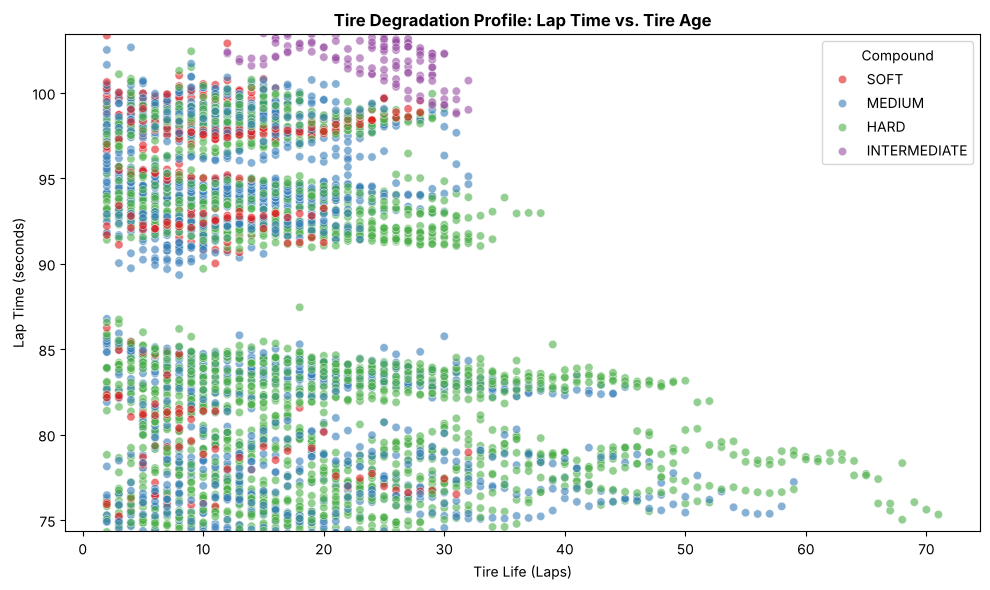

Race
Monaco          77.2730
Monza           83.5700
Suzuka          93.1960
Bahrain         98.4480
Silverstone    102.9655
Name: LapTime_s, dtype: float64


In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_valid,
    x='TyreLife',
    y='LapTime_s',
    hue='Compound',
    alpha=0.6,
    palette='Set1'
)
plt.title("Tire Degradation Profile: Lap Time vs. Tire Age", fontweight='bold')
plt.xlabel("Tire Life (Laps)")
plt.ylabel("Lap Time (seconds)")
plt.ylim(df_valid['LapTime_s'].quantile(0.01), df_valid['LapTime_s'].quantile(0.95))
plt.tight_layout()
plt.savefig("../reports/figures/tire_degradation_profile.png", dpi=300)
plt.show()

# Median lap time per race
print(df_valid.groupby('Race')['LapTime_s'].median().sort_values())

### Findings
- The horizontal bands are **different tracks**, not a tyre effect. Median lap times range from about **77 s at Monaco** to about **103 s at Silverstone**.
- All **Intermediate** laps come from Silverstone, the only wet race.
- Because tracks are mixed, this chart cannot measure tyre wear on its own. The per-compound degradation analysis, which separates tyre wear from fuel burn, is in `Gavin_tyre_degradation.ipynb`.